<a href="https://colab.research.google.com/github/ogorgodze/PythonCodes/blob/main/Basel_III.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

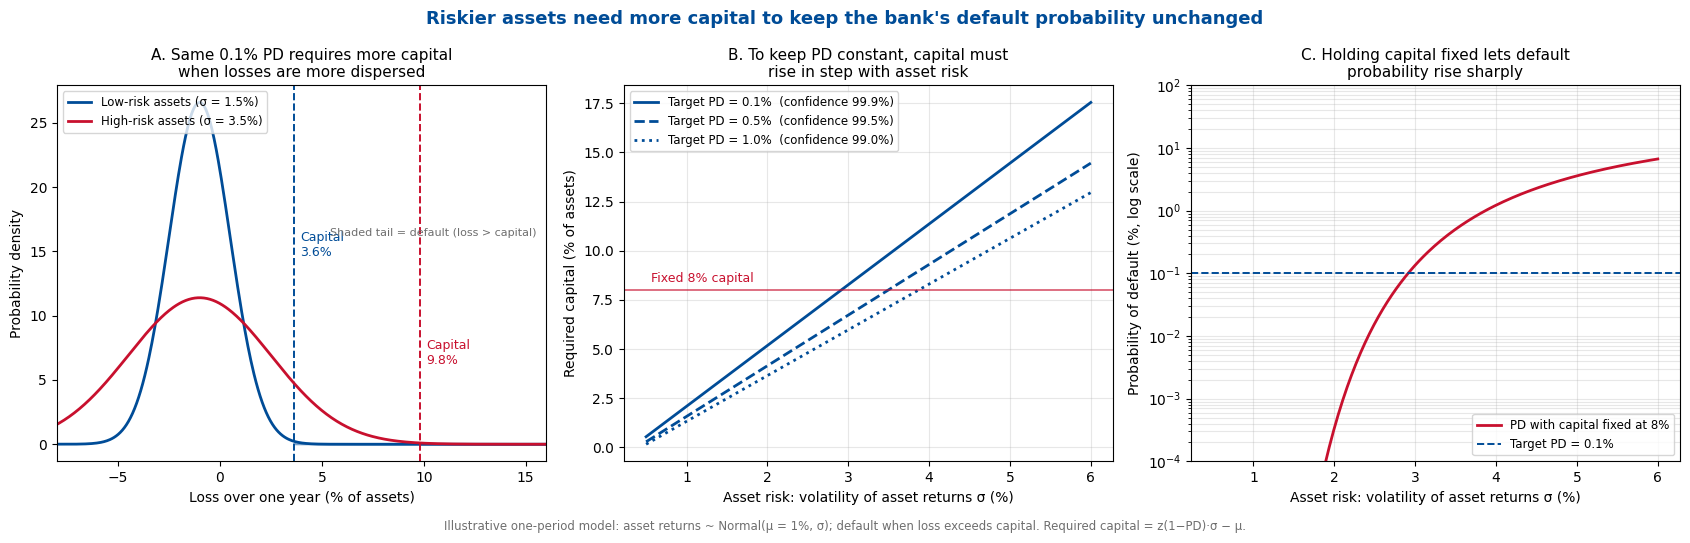

In [ ]:
"""
Capital needed to hold a bank's default probability constant as asset risk rises.

Model (one-period Merton-type bank):
  - Assets A0 = 100 funded by debt D and equity (capital) K = A0 - D.
  - One-year asset return R ~ Normal(mu, sigma).
  - The bank defaults if the asset loss exceeds capital: A0*(-R) > K.
  - PD = P(R < -K/A0) = Phi((-K/A0 - mu) / sigma)
  - Capital for a target PD: K/A0 = -(mu + sigma * Phi^-1(PD)) = z(1-PD)*sigma - mu
  => With PD fixed, required capital rises linearly with asset volatility.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

MU = 0.01                        # expected asset return (covers expected loss via margins)
TARGET_PDS = [0.001, 0.005, 0.01]  # 0.1% (~99.9% confidence, IRB calibration), 0.5%, 1%
FIXED_K = 0.08                   # capital ratio held fixed for comparison (8%)
sigmas = np.linspace(0.005, 0.06, 200)

def required_capital(sigma, pd, mu=MU):
    return np.maximum(norm.ppf(1 - pd) * sigma - mu, 0)

def pd_given_capital(sigma, k, mu=MU):
    return norm.cdf((-k - mu) / sigma)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
navy, red, grey = "#004C97", "#C8102E", "#6E6E6E"

# Panel A: loss distributions for a low-risk and a high-risk bank, same 0.1% PD
ax = axes[0]
x = np.linspace(-0.10, 0.20, 600)                 # loss as % of assets (= -R)
for sigma, col, lab in [(0.015, navy, "Low-risk assets (σ = 1.5%)"),
                        (0.035, red, "High-risk assets (σ = 3.5%)")]:
    dens = norm.pdf(x, loc=-MU, scale=sigma)
    k = required_capital(sigma, 0.001)
    ax.plot(x * 100, dens, color=col, lw=2, label=lab)
    tail = x >= k
    ax.fill_between(x[tail] * 100, dens[tail], color=col, alpha=0.35)
    ax.axvline(k * 100, color=col, ls="--", lw=1.4)
    ax.text(k * 100 + 0.3, ax.get_ylim()[1] * 0.0 + max(dens) * 0.55,
            f"Capital\n{k*100:.1f}%", color=col, fontsize=9)
ax.set_title("A. Same 0.1% PD requires more capital\nwhen losses are more dispersed", fontsize=11)
ax.set_xlabel("Loss over one year (% of assets)")
ax.set_ylabel("Probability density")
ax.set_xlim(-8, 16)
ax.legend(fontsize=8.5, loc="upper left")
ax.text(0.98, 0.60, "Shaded tail = default (loss > capital)", transform=ax.transAxes,
        ha="right", fontsize=8, color=grey)

# Panel B: required capital vs asset risk, for several target PDs
ax = axes[1]
for pd, ls in zip(TARGET_PDS, ["-", "--", ":"]):
    ax.plot(sigmas * 100, required_capital(sigmas, pd) * 100, color=navy, ls=ls, lw=2,
            label=f"Target PD = {pd*100:.1f}%  (confidence {100*(1-pd):.1f}%)")
ax.axhline(FIXED_K * 100, color=red, lw=1.2, alpha=0.7)
ax.text(sigmas[2] * 100, FIXED_K * 100 + 0.4, "Fixed 8% capital", color=red, fontsize=9)
ax.set_title("B. To keep PD constant, capital must\nrise in step with asset risk", fontsize=11)
ax.set_xlabel("Asset risk: volatility of asset returns σ (%)")
ax.set_ylabel("Required capital (% of assets)")
ax.legend(fontsize=8.5, loc="upper left")
ax.grid(alpha=0.3)

# Panel C: what happens if capital is NOT increased
ax = axes[2]
pds = pd_given_capital(sigmas, FIXED_K) * 100
ax.plot(sigmas * 100, pds, color=red, lw=2, label="PD with capital fixed at 8%")
ax.axhline(0.1, color=navy, ls="--", lw=1.4, label="Target PD = 0.1%")
ax.set_yscale("log")
ax.set_ylim(1e-4, 100)
ax.set_title("C. Holding capital fixed lets default\nprobability rise sharply", fontsize=11)
ax.set_xlabel("Asset risk: volatility of asset returns σ (%)")
ax.set_ylabel("Probability of default (%, log scale)")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(alpha=0.3, which="both")

fig.suptitle("Riskier assets need more capital to keep the bank's default probability unchanged",
             fontsize=13, fontweight="bold", color=navy)
fig.text(0.5, -0.02, "Illustrative one-period model: asset returns ~ Normal(μ = 1%, σ); "
         "default when loss exceeds capital. Required capital = z(1−PD)·σ − μ.",
         ha="center", fontsize=8.5, color=grey)
plt.tight_layout()
plt.savefig("capital_vs_risk.png", dpi=200, bbox_inches="tight")
plt.show()


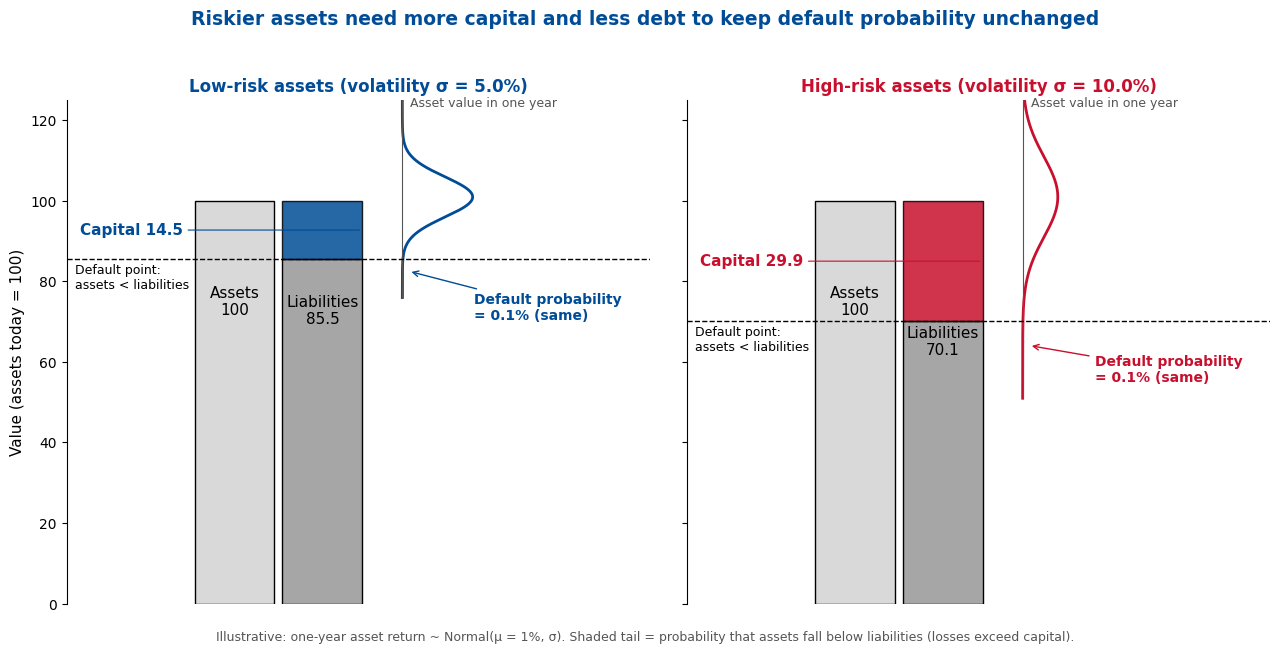

In [ ]:
"""
Riskier assets need more capital (and less debt funding) to keep the same default probability.

Each panel shows a bank's balance sheet today (assets = liabilities + capital) and,
rotated to the right, the distribution of its asset value in one year. The bank defaults
if assets fall below liabilities, i.e. if losses exceed capital. Both banks are funded so
that this probability (shaded tail) is the same 0.1%.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import norm

A0, MU, PD = 100.0, 0.01, 0.001          # assets today, expected return, target PD
z = norm.ppf(1 - PD)
navy, red, grey, light = "#004C97", "#C8102E", "#555555", "#D9D9D9"

banks = [("Low-risk assets", 0.05, navy), ("High-risk assets", 0.10, red)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for ax, (name, sigma, col) in zip(axes, banks):
    K = (z * sigma - MU) * A0             # capital needed for target PD
    L = A0 - K                            # liabilities
    mean, sd = A0 * (1 + MU), A0 * sigma

    # Balance sheet: assets (left column), liabilities + capital (right column)
    ax.add_patch(Rectangle((0, 0), 1, A0, fc=light, ec="black"))
    ax.add_patch(Rectangle((1.1, 0), 1, L, fc="#A6A6A6", ec="black"))
    ax.add_patch(Rectangle((1.1, L), 1, K, fc=col, ec="black", alpha=0.85))
    ax.text(0.5, 75, f"Assets\n{A0:.0f}", ha="center", va="center", fontsize=11)
    ax.text(1.6, (60 + L) / 2, f"Liabilities\n{L:.1f}", ha="center", va="center", fontsize=11)
    ax.annotate(f"Capital {K:.1f}", xy=(2.1, L + K / 2), xytext=(-0.15, L + K / 2),
                ha="right", va="center", fontsize=11, color=col, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=col, lw=0.8))

    # Rotated distribution of asset value in one year
    y = np.linspace(mean - 5 * sd, mean + 5 * sd, 500)
    dens = norm.pdf(y, mean, sd)
    width = 2.2 * dens / norm.pdf(mean, mean, 0.02 * A0)   # common scale for both panels
    x0 = 2.6
    ax.plot(x0 + width, y, color=col, lw=2)
    ax.plot([x0, x0], [y[0], y[-1]], color=grey, lw=0.8)
    tail = y <= L
    ax.fill_betweenx(y[tail], x0, x0 + width[tail], color=col, alpha=0.5)

    # Default threshold
    ax.axhline(L, xmin=0.0, xmax=1, color="black", ls="--", lw=1)
    ax.text(-1.5, L - 1.0, "Default point:\nassets < liabilities", ha="left", va="top", fontsize=9)
    ax.annotate(f"Default probability\n= {PD*100:.1f}% (same)", xy=(x0 + 0.08, L - 0.6 * sd),
                xytext=(x0 + 0.9, L - 15), fontsize=10, color=col, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=col))
    ax.text(x0 + 0.1, min(y[-1], 123) + 0.5, "Asset value in one year", fontsize=9, color=grey)

    ax.set_title(f"{name} (volatility σ = {sigma*100:.1f}%)", fontsize=12, color=col, fontweight="bold")
    ax.set_xlim(-1.6, 5.7)
    ax.set_ylim(0, 125)
    ax.set_xticks([])
    for s in ["top", "right", "bottom"]:
        ax.spines[s].set_visible(False)

axes[0].set_ylabel("Value (assets today = 100)", fontsize=11)
fig.suptitle("Riskier assets need more capital and less debt to keep default probability unchanged",
             fontsize=13.5, fontweight="bold", color=navy)
fig.text(0.5, 0.01, "Illustrative: one-year asset return ~ Normal(μ = 1%, σ). Shaded tail = probability "
         "that assets fall below liabilities (losses exceed capital).",
         ha="center", fontsize=9, color=grey)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("capital_vs_risk_panelA.png", dpi=200, bbox_inches="tight")


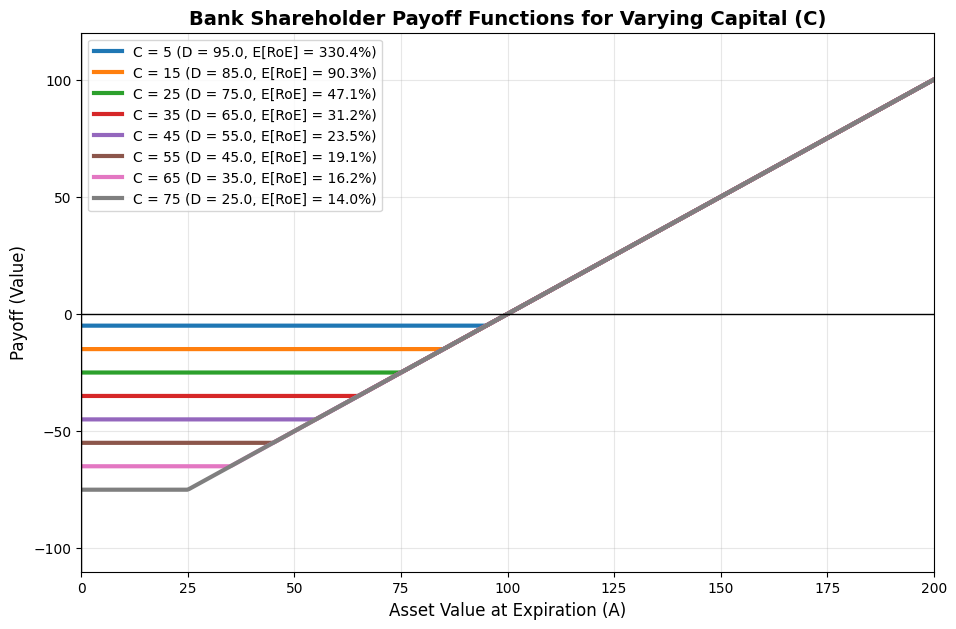

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# --- 1. Define Constant Parameters ---
A0 = 100.0   # Initial asset value at t=0
r = 0.10     # Risk-free rate (drift of the asset)
sigma = 0.30 # Volatility of the asset
T = 1.0      # Time horizon (years)

# --- 2. Define Range for Capital C ---
C_values = [5, 15, 25 , 35, 45, 55, 65, 75]

# --- 3. Plotting Setup ---
plt.figure(figsize=(11, 7))
A_plot = np.linspace(0, 200, 500)

# Loop through each C value to calculate and plot the payoff function
for C in C_values:
    D = A0 - C  # Deposit obligation (Strike price K)

    # Calculate d1 and d2 for the Black-Scholes formula
    # Handle edge case where D <= 0 (all equity funded bank)
    if D > 0:
        d1 = (np.log(A0 / D) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        # Expected call payoff
        C0 = A0 * np.exp(r * T) * norm.cdf(d1) - D * norm.cdf(d2)
    else:
        # If D <= 0, the option payoff is simply A_T - D
        C0 = A0 * np.exp(r * T) - D

    # f(0) = -C
    f_0 = -C

    RoE=(C0-C)/C*100

    # Option payoff shifted by f(0): max(A - D, 0) - C
    term1 = np.maximum(A_plot - D, 0) + f_0

    plt.plot(A_plot, term1, label=f'C = {C} D = {D:.1f}, E[RoE] = {RoE:.1f}%', lw=3)

# Formatting the plot
plt.title('Bank Shareholder Payoff Functions for Varying Capital (C)', fontsize=14, fontweight='bold')
plt.xlabel('Asset Value at Expiration (A)', fontsize=12)
plt.ylabel('Payoff (Value)', fontsize=12)
plt.axhline(0, color='black', linewidth=1, linestyle='-')  # Zero line
plt.axvline(0, color='black', linewidth=1, linestyle='-')  # Zero line for A
plt.ylim(-110, 120)
plt.xlim(0, 200)
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
  Profit=C0-C
  print(Profit)

10.517091807564768
